# Session 0: Computing and Collaboration for Total Beginners

Welcome to the quant club. This notebook is a gentle first pass through the tools we will use for financial research. Work from top to bottom, change values, and read the output rather than trying to memorize every command.

## Learning goals

By the end, you should be able to:

- run Python code and interpret simple errors;
- use variables, lists, dictionaries, loops, conditionals, and functions;
- inspect and clean a small pandas `DataFrame`;
- create a basic price and return chart; and
- describe the Git steps used to share reproducible work.

## How to use this notebook

Run each cell with **Shift+Enter**. A code cell can depend on variables created above it, so execution order matters. If outputs become confusing, restart the kernel and run all cells from the top. Before sharing work, do one clean-kernel rerun so that the notebook does not depend on hidden state.

The cells marked **Try it** are deliberately unfinished prompts. Make a small change, run the cell, and observe what happens.

## 1. Python building blocks

Python values can be stored in variables. Strings hold text, numbers support calculations, lists hold ordered values, and dictionaries associate names with values.

In [7]:
club_name = 'Nova Quant Club'
starting_price = 100.0
prices = [100, 101.5, 100.8, 102.2, 101.9]
asset = {
    'ticker': 'DEMO',
    'market': 'synthetic',
    'currency': 'USD',
}

print(club_name)
print(f'{asset["ticker"]} starts at ${starting_price:.2f}')
print(f'There are {len(prices)} daily changes.')

Nova Quant Club
DEMO starts at $100.00
There are 5 daily changes.


In [8]:
daily_changes = [0.02, -0.01, 0.015, 0.0]

positive_days = []

for price_change in daily_changes:
    if price_change > 0:
        positive_days.append(price_change)

print('Positive changes:', positive_days)
print('Largest observed price:', max(prices))

Positive changes: [0.02, 0.015]
Largest observed price: 102.2


### Try it

Change one value in `prices`, add another daily change, or change the condition so that it keeps only negative days.

## 2. Write a function

Functions package a repeatable calculation. This one summarizes a list of prices and returns a dictionary that is easy to inspect or pass to another function.

In [21]:
def summarize_prices(price_list):
    return {
        'count': len(price_list),
        'first_price': price_list[0],
        'last_price': price_list[-1],
        'minimum': min(price_list),
        'maximum': max(price_list),
    }

summary = summarize_prices(prices)
summary

{'count': 5,
 'first_price': 100,
 'last_price': 101.9,
 'minimum': 100,
 'maximum': 102.2}

## 3. Create a small market dataset

This dataset is synthetic and reproducible. It lets us practice the workflow without an API key, internet connection, or downloaded file. Real research must record the data source, timestamp, assumptions, and any transformations.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seed = 7
rng = np.random.default_rng(seed=seed)
dates = pd.date_range('2025-01-02', periods=60, freq='B')
daily_returns = rng.normal(loc=0.0004, scale=0.012, size=len(dates))
close = 100 * np.cumprod(1 + daily_returns)
market_data = pd.DataFrame({'close': close}, index=dates)
market_data.index.name = 'date'
market_data.loc[dates[12], 'close'] = np.nan
market_data.head()

,close
date,
2025-01-02,100.041476
2025-01-03,100.440136
2025-01-06,100.149899
2025-01-07,99.119647
2025-01-08,98.618493


## 4. Inspect a DataFrame

These commands answer different questions: `head` shows examples, `shape` gives rows and columns, `info` reports types and missing values, and `describe` provides numeric summary statistics.

In [21]:
print('First five rows:')
display(market_data.head())
print('Shape:', market_data.shape)
market_data.info()
display(market_data.describe())

First five rows:


,close
date,
2025-01-02,100.041476
2025-01-03,100.440136
2025-01-06,100.149899
2025-01-07,99.119647
2025-01-08,98.618493


Shape: (60, 1)
<class 'pandas.DataFrame'>
DatetimeIndex: 60 entries, 2025-01-02 to 2025-03-26
Freq: B
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   close   59 non-null     float64
dtypes: float64(1)
memory usage: 3.0 KB


,close
count,59.000000
mean,89.791382
std,6.210764
min,82.865918
25%,84.381033
50%,86.935003
75%,97.462269
max,100.440136


In [16]:
close_prices = market_data['close']
selected_rows = market_data.loc['2025-01-12':'2025-01-18']
missing_count = market_data['close'].isna().sum()
print('Missing close values:', missing_count)
display(selected_rows)

Missing close values: 1


,close
date,
2025-01-12,98.576004
2025-01-13,99.037601
2025-01-14,NaN
2025-01-15,98.134519
2025-01-16,98.139326
2025-01-17,98.997421
2025-01-18,97.440134


### Handle missing values

For this teaching example, forward-filling means using the last known close. That choice is not automatically correct for every dataset; document the rule you choose and check that it does not introduce look-ahead bias.

In [17]:
clean_data = market_data.copy()
clean_data['close'] = clean_data['close'].ffill()
clean_data['return'] = clean_data['close'].pct_change()
clean_data.loc['2025-01-12':'2025-01-18']


,close,return
date,,
2025-01-12,98.576004,0.006278
2025-01-13,99.037601,0.004683
2025-01-14,99.037601,0.000000
2025-01-15,98.134519,-0.009119
2025-01-16,98.139326,0.000049
2025-01-17,98.997421,0.008744
2025-01-18,97.440134,-0.015731


## 5. Make a simple plot

A chart is useful for checking whether the data looks plausible. The return chart starts with a missing value because there is no previous close for the first observation.

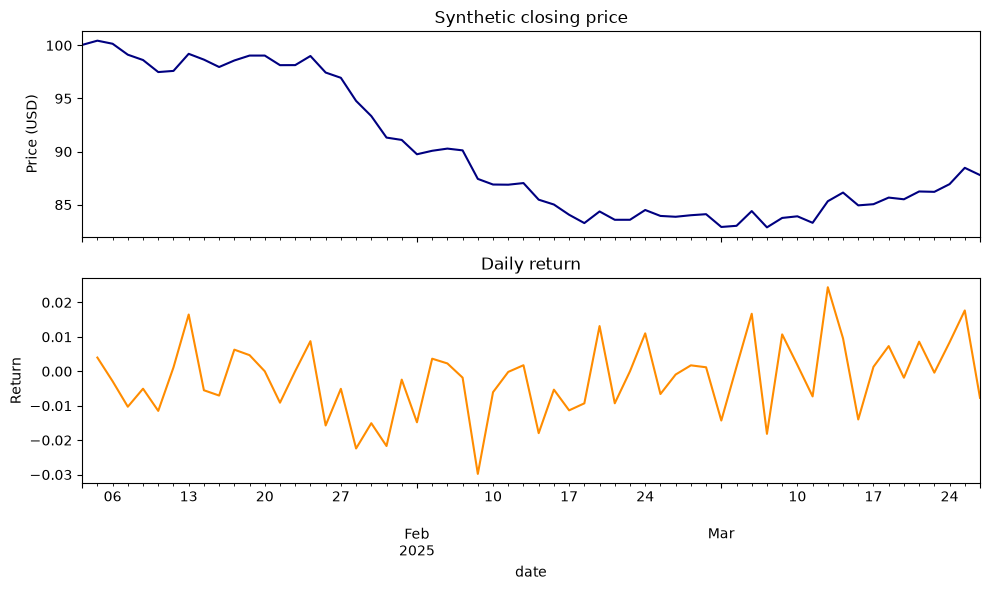

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
clean_data['close'].plot(ax=axes[0], color='navy', title='Synthetic closing price')
clean_data['return'].plot(ax=axes[1], color='darkorange', title='Daily return')
axes[0].set_ylabel('Price (USD)')
axes[1].set_ylabel('Return')
plt.tight_layout()
plt.show()

### Try it

Change the chart colors, plot only the first 20 observations, or add a 5-day moving average with `clean_data['close'].rolling(5).mean()`.

## 6. Python classes

A class defines a blueprint for an object. It can hold data and functions that operate on that data. In quant work, classes are useful for keeping portfolio, signal, or trade objects organized.


A class defines a blueprint for an object. It can hold data and functions that operate on that data. In quant work, classes are useful for keeping portfolio, signal, or trade objects organized.

```python
class Position:
    def __init__(self, ticker, shares, price):
        self.ticker = ticker
        self.shares = shares
        self.price = price

    def market_value(self):
        return self.shares * self.price

    def __repr__(self):
        return f"Position({self.ticker}, shares={self.shares}, price={self.price})"

p = Position('AAPL', 10, 210.25)
print(p.market_value())
print(p)
```

This example stores the stock symbol, share count, and price in one object. The method `market_value()` computes the value from those internal attributes.

### Try it

Create a second class, such as `Portfolio`, that stores a list of `Position` objects and adds a total value method.


## 7. Git collaboration basics

A typical small change follows this pattern in a terminal:

```text
git status
git add .
git commit -m "Add Session 0 notebook"
git pull
git push
```

`git status` shows what changed. `git add` stages selected files. `git commit` records a local snapshot. `git pull` gets teammates' latest work, and `git push` shares your commits. Never commit passwords, API keys, private data, or credentials; use environment variables or a local ignored file instead.


## Session 0 checklist

- [ ] I can run a cell and explain what its output shows.
- [ ] I can create and update a variable, list, and dictionary.
- [ ] I can write a loop, conditional, and simple function.
- [ ] I can inspect a DataFrame with `head`, `shape`, `info`, and `describe`.
- [ ] I can select columns and rows and explain how missing values were handled.
- [ ] I can make a basic price or return plot.
- [ ] I know the difference between a local Git commit and a pushed commit.
- [ ] I will rerun this notebook from a clean kernel before sharing it.

Next step: keep this notebook as a practice space. Small experiments are encouraged; record what you changed and what you learned in a Markdown cell.